# 08_04 Mutual Information

**Learning objectives**
- Define **mutual information** $I(X;Y)$ as the KL divergence between the joint distribution and the product of the marginals, and as the **reduction in entropy** $H(X)-H(X\mid Y)$.
- Compute it for discrete tables, estimate it from data (**plug-in**, bias correction, **KSG nearest-neighbour** estimator), and know that for a bivariate normal $I=-\tfrac12\ln(1-\rho^2)$.
- Explain why MI **detects nonlinear dependence that correlation misses**, and why it is the basis of **information gain** and **feature selection**.
- Test independence with the **G-test** ($2n\,\hat I\sim\chi^2$) and calibrate MI estimates against a permutation baseline.

**Prerequisites:** [08_01 Entropy and cross-entropy](08_01_entropy_cross_entropy.ipynb), [08_02 KL and JS divergence](08_02_kl_js_divergence.ipynb), [03_01 Multivariate normal](../../module_03_multivariate/notebooks/03_01_multivariate_normal.ipynb).

## 1. Setup

All imports in one cell; the generator is seeded so every run gives the same numbers.

In [1]:
import sys
sys.path.append("../..")  # repo root, so common.style can be imported
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.graph_objects as go
from scipy import stats
from common.style import apply_style, MAIN, SIM, HIGHLIGHT, NEUTRAL, COLORS

apply_style()
rng = np.random.default_rng(42)  # fixed seed so every run gives the same numbers

## 2. Prerequisite recap
A joint distribution $p(x,y)$ has marginals $p(x)=\sum_yp(x,y)$ and $p(y)$; $X$ and $Y$ are independent iff $p(x,y)=p(x)p(y)$ for all pairs. Entropy is $H(X)=-\sum p\ln p$ (08_01), and $\mathrm{KL}(p\|q)\ge0$ with equality iff $p=q$ (08_02). The Pearson correlation measures only the *linear* association.

## 3. Intuition and story
You are choosing which of fifty customer features to feed a churn model. A feature is useful if knowing it **reduces your uncertainty about churn**. That reduction, measured in nats or bits, is the **mutual information** between the feature and the label. It is zero when the feature is useless (independent of churn) and it does not care *how* the feature is related to churn: a feature whose relation is U-shaped (young and old customers leave, middle-aged ones stay) has near-zero correlation but a large mutual information.

Mutual information is also the *distance from independence*: it is the KL divergence between the real joint distribution and the fictitious one in which the two variables ignore each other.

## 4. Formal definitions

For a pair $(X,Y)$ with joint pmf $p(x,y)$ and marginals $p(x),p(y)$:

$$I(X;Y)=\sum_{x,y}p(x,y)\ln\frac{p(x,y)}{p(x)p(y)}=\mathrm{KL}\big(p_{XY}\,\|\,p_X\otimes p_Y\big).$$

| Identity | Meaning |
|---|---|
| $I(X;Y)=H(X)-H(X\mid Y)=H(Y)-H(Y\mid X)$ | uncertainty removed by learning the other variable |
| $I(X;Y)=H(X)+H(Y)-H(X,Y)$ | overlap of the two entropies |
| $I(X;X)=H(X)$ | a variable shares all its entropy with itself |
| $0\le I(X;Y)\le\min\{H(X),H(Y)\}$ | $0$ iff independent |
| **Data processing:** $X\to Y\to Z\Rightarrow I(X;Z)\le I(X;Y)$ | no processing creates information |
| **Conditional MI** $I(X;Y\mid Z)=H(X\mid Z)-H(X\mid Y,Z)$ | information about $X$ in $Y$ beyond $Z$ |
| **Normalised MI** | $\mathrm{NMI}=I(X;Y)/\sqrt{H(X)H(Y)}\in[0,1]$ |
| **Bivariate normal** | $I(X;Y)=-\tfrac12\ln(1-\rho^2)$ |
| **Information gain** of a split $S$ of $Y$ | $\mathrm{IG}=H(Y)-H(Y\mid S)=I(Y;S)$ |

## 5. Derivations

### 5.1 $I\ge0$ and $I=0$ iff independent
$I$ is a KL divergence, so Gibbs' inequality (08_02) gives $I\ge0$ with equality exactly when $p(x,y)=p(x)p(y)$. **In plain words.** Learning one variable can never make you *more* uncertain about the other on average, and it helps only if they are dependent.

### 5.2 The entropy form
$I=\sum p(x,y)[\ln p(x,y)-\ln p(x)-\ln p(y)]=-H(X,Y)+H(X)+H(Y)$, and using the chain rule $H(X,Y)=H(Y)+H(X\mid Y)$ gives $I=H(X)-H(X\mid Y)$. **In plain words.** MI is how much of $X$'s surprise disappears once $Y$ is known.

### 5.3 Bivariate normal
For $(X,Y)$ standard bivariate normal with correlation $\rho$: $h(X,Y)=\ln(2\pi e)+\tfrac12\ln(1-\rho^2)$ and $h(X)=h(Y)=\tfrac12\ln(2\pi e)$, so $I=h(X)+h(Y)-h(X,Y)=-\tfrac12\ln(1-\rho^2)$. **In plain words.** For Gaussian data MI is a function of correlation alone: 0 at $\rho=0$, 0.51 nats at $\rho=0.8$, and it grows without bound as $\rho\to\pm1$ (the pair becomes deterministic).

### 5.4 Why correlation can miss dependence
If $Y=X^2$ with $X$ symmetric about zero then $\mathrm{Cov}(X,Y)=E[X^3]-E[X]E[X^2]=0$, yet $Y$ is a function of $X$ so $I(X;Y)=H(Y)$ (for discretised variables, the entropy of $Y$). **In plain words.** Correlation asks "do they rise together?", mutual information asks "does knowing one tell me anything about the other?"; a perfect U-shape answers yes to the second and no to the first.

### 5.5 Estimating MI from data
*Plug-in:* replace $p$ by the observed frequencies in an $r\times c$ table. The estimate is biased **upwards**: under independence $E[\hat I]\approx\frac{(r-1)(c-1)}{2n}$, because $2n\hat I$ is the G statistic (08_02), which is $\chi^2_{(r-1)(c-1)}$ with mean $(r-1)(c-1)$. *Kraskov-Stoegbauer-Grassberger (KSG):* for continuous variables use nearest-neighbour distances: $\hat I=\psi(k)+\psi(n)-\frac1n\sum_i[\psi(n_x(i)+1)+\psi(n_y(i)+1)]$ with $\psi$ the digamma function. **In plain words.** Counting cells gives a slightly inflated number that must be compared with the noise level of an independent pair; neighbour methods avoid binning but need a consistent scale.

### 5.6 Information gain and the G-test of independence
For a binary split $S$ of a label $Y$, $\mathrm{IG}=I(Y;S)$. For a contingency table $G=2n\,\hat I$ is the likelihood-ratio statistic of independence, $\chi^2_{(r-1)(c-1)}$ under the null (06_04, 08_02). **In plain words.** The criterion that a decision tree uses to choose a split, and the test statistic that decides whether two categorical variables are associated, are the same quantity.

## 6. Properties and relationships
- **Symmetric**, non-negative, invariant under invertible transformations of $X$ or $Y$ (relabelling or monotone rescaling), unlike correlation.
- **Not additive over features:** $I(Y;X_1,X_2)\ne I(Y;X_1)+I(Y;X_2)$ in general; redundant features overlap (a duplicate adds nothing) and complementary features can be worth more together (XOR).
- **Units:** nats or bits; normalise (NMI) to compare across variables with different entropies.
- **Estimation difficulty:** MI of continuous variables is hard to estimate in high dimension; binning is sensitive to bin number; always compare with a permutation baseline.
- **Link to ML and AI:** feature selection (filter methods, mRMR), decision-tree splits (information gain), clustering evaluation (NMI), representation learning (InfoNCE, mutual-information maximisation), the **information bottleneck**, and independent component analysis.

## 7. Helpers

A plug-in estimator for tables, the Miller-Madow style bias term, and a KSG estimator for continuous pairs, written from scratch.

In [2]:
from scipy.special import digamma
from scipy.spatial import cKDTree
def mi_table(C):
    # plug-in mutual information (nats) of a contingency table of counts
    P = np.asarray(C, float); P = P / P.sum(); px = P.sum(axis=1, keepdims=True); py = P.sum(axis=0, keepdims=True); m = P > 0
    return float((P[m] * np.log(P[m] / (px @ py)[m])).sum())
def ent(p):
    p = np.asarray(p, float); p = p[p > 0]; return float(-(p * np.log(p)).sum())
def ksg(x, y, k=5):
    x = np.asarray(x, float).reshape(len(x), -1); y = np.asarray(y, float).reshape(len(y), -1); n = len(x)
    z = np.hstack([x, y]); d, _ = cKDTree(z).query(z, k=k + 1, p=np.inf); eps = d[:, -1] - 1e-12
    nx = cKDTree(x).query_ball_point(x, eps, p=np.inf, return_length=True) - 1; ny = cKDTree(y).query_ball_point(y, eps, p=np.inf, return_length=True) - 1
    return float(digamma(k) + digamma(n) - np.mean(digamma(nx + 1) + digamma(ny + 1)))
Cd = np.array([[40, 10], [10, 40]]); Pd = Cd / Cd.sum()
print("I from the table:", mi_table(Cd), "| H(X) + H(Y) - H(X,Y):", ent(Pd.sum(1)) + ent(Pd.sum(0)) - ent(Pd.ravel()), "| KL(joint || product):", stats.entropy(Pd.ravel(), np.outer(Pd.sum(1), Pd.sum(0)).ravel()))
rho = 0.8; g = np.random.default_rng(0); xy = g.multivariate_normal([0, 0], [[1, rho], [rho, 1]], 3000); print("KSG for rho = 0.8:", ksg(xy[:, 0], xy[:, 1]), "| theory:", -0.5 * np.log(1 - rho ** 2))
assert abs(mi_table(Cd) - (ent(Pd.sum(1)) + ent(Pd.sum(0)) - ent(Pd.ravel()))) < 1e-12 and abs(ksg(xy[:, 0], xy[:, 1]) + 0.5 * np.log(1 - rho ** 2)) < 0.04

I from the table: 0.19274475702175753 | H(X) + H(Y) - H(X,Y): 0.1927447570217573 | KL(joint || product): 0.19274475702175753


KSG for rho = 0.8: 0.5218202642855907 | theory: 0.5108256237659908


## 8. 2D visuals

### 8.1 The entropy diagram
For a joint table of a binary feature and a binary label the bars show $H(X)$, $H(Y)$, the joint $H(X,Y)$ and the overlap $I(X;Y)$; $H(X\mid Y)=H(X)-I$.

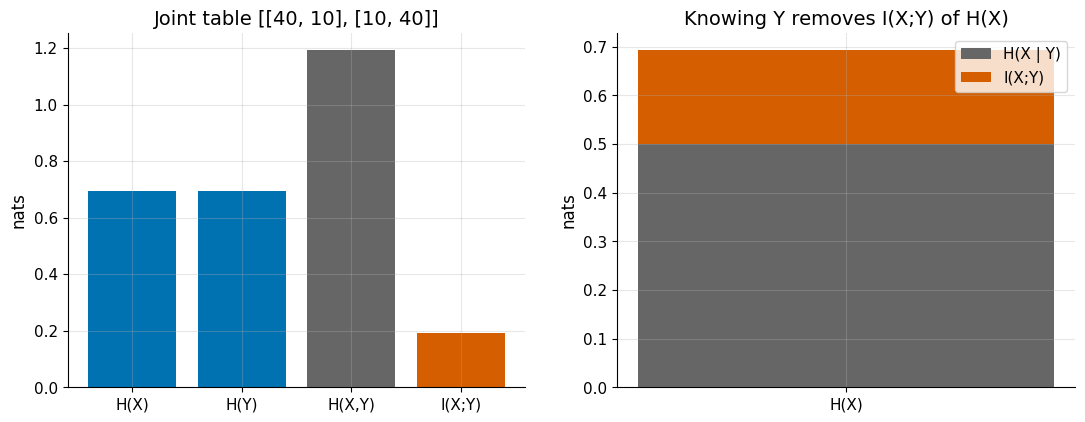

H(X) = 0.6931, H(Y) = 0.6931, H(X,Y) = 1.1935, I = 0.1927, H(X|Y) = 0.5004


In [3]:
Hx, Hy, Hxy, Ixy = ent(Pd.sum(1)), ent(Pd.sum(0)), ent(Pd.ravel()), mi_table(Cd); fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
axes[0].bar(["H(X)", "H(Y)", "H(X,Y)"], [Hx, Hy, Hxy], color=[MAIN, MAIN, NEUTRAL]); axes[0].bar(["I(X;Y)"], [Ixy], color=HIGHLIGHT); axes[0].set_ylabel("nats"); axes[0].set_title("Joint table [[40, 10], [10, 40]]")
axes[1].bar(["H(X)"], [Hx - Ixy], color=NEUTRAL, label="H(X | Y)"); axes[1].bar(["H(X)"], [Ixy], bottom=[Hx - Ixy], color=HIGHLIGHT, label="I(X;Y)"); axes[1].legend(); axes[1].set_ylabel("nats"); axes[1].set_title("Knowing Y removes I(X;Y) of H(X)")
plt.show(); print(f"H(X) = {Hx:.4f}, H(Y) = {Hy:.4f}, H(X,Y) = {Hxy:.4f}, I = {Ixy:.4f}, H(X|Y) = {Hxy - Hy:.4f}"); assert abs(Hxy - Hy - (Hx - Ixy)) < 1e-12

### 8.2 Mutual information against correlation for Gaussian data
The curve $-\tfrac12\ln(1-\rho^2)$ and KSG estimates from 2,000-point samples (mean of 20 repeats).

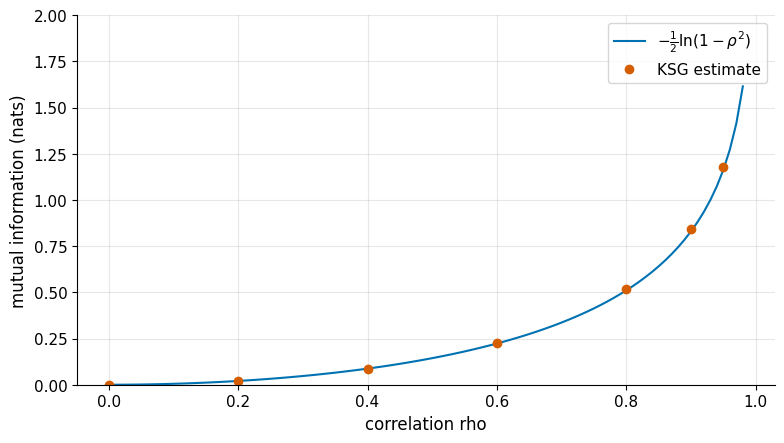

{0.0: np.float64(0.0007), 0.2: np.float64(0.0181), 0.4: np.float64(0.0853), 0.6: np.float64(0.2285), 0.8: np.float64(0.5173), 0.9: np.float64(0.8431), 0.95: np.float64(1.1794)} | theory: [-0.      0.0204  0.0872  0.2231  0.5108  0.8304  1.164 ]


In [4]:
rg = np.linspace(0, 0.98, 99); rr_ = np.array([0, 0.2, 0.4, 0.6, 0.8, 0.9, 0.95]); ks_ = [np.mean([ksg(*np.random.default_rng(100 * i + j).multivariate_normal([0, 0], [[1, r], [r, 1]], 2000).T) for j in range(20)]) for i, r in enumerate(rr_)]
fig, ax = plt.subplots(figsize=(9, 4.8)); ax.plot(rg, -0.5 * np.log(1 - rg ** 2), color=MAIN, label="$-\\frac{1}{2}\\ln(1-\\rho^2)$"); ax.plot(rr_, ks_, "o", color=HIGHLIGHT, label="KSG estimate"); ax.set_xlabel("correlation rho"); ax.set_ylabel("mutual information (nats)"); ax.legend(); ax.set_ylim(0, 2); plt.show()
print({float(r): round(v, 4) for r, v in zip(rr_, ks_)}, "| theory:", np.round(-0.5 * np.log(1 - rr_ ** 2), 4)); assert all(abs(v - (-0.5 * np.log(1 - r ** 2))) < 0.04 for r, v in zip(rr_, ks_))

### 8.3 Same correlation, different dependence
Four datasets of 2,000 points. Correlation sees only the first; mutual information (KSG) sees the dependence in the quadratic and the circle, and reads zero for the independent cloud.

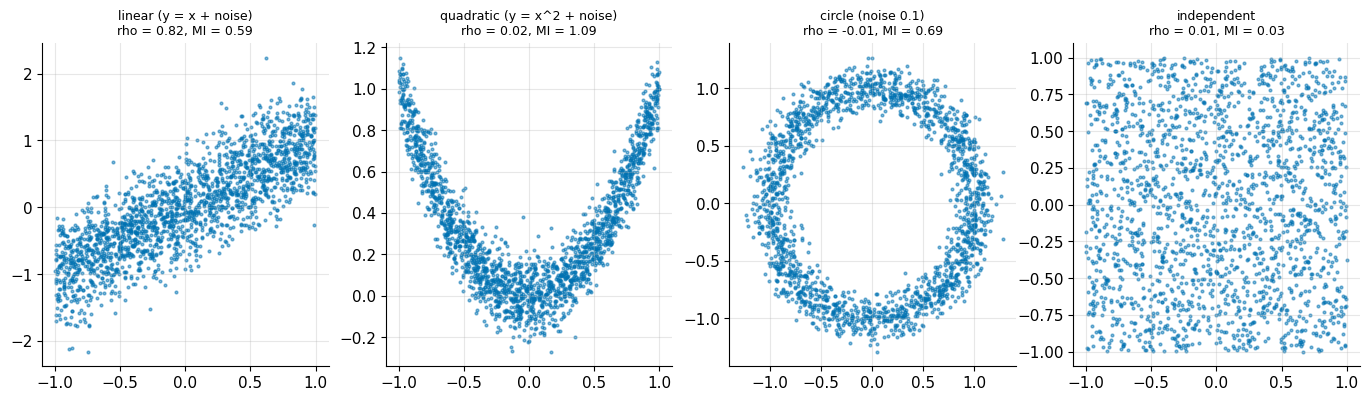

{'linear (y = x + noise)': (np.float64(0.822), 0.586), 'quadratic (y = x^2 + noise)': (np.float64(0.018), 1.093), 'circle (noise 0.1)': (np.float64(-0.006), 0.686), 'independent': (np.float64(0.011), 0.027)}


In [5]:
g = np.random.default_rng(7); n4 = 2000; xa = g.uniform(-1, 1, n4); th = g.uniform(0, 2 * np.pi, n4)
sets = {"linear (y = x + noise)": (xa, xa + 0.4 * g.normal(size=n4)), "quadratic (y = x^2 + noise)": (xa, xa ** 2 + 0.1 * g.normal(size=n4)), "circle (noise 0.1)": (np.cos(th) + 0.1 * g.normal(size=n4), np.sin(th) + 0.1 * g.normal(size=n4)), "independent": (g.uniform(-1, 1, n4), g.uniform(-1, 1, n4))}
fig, axes = plt.subplots(1, 4, figsize=(17, 4.2)); res4 = {}
for ax, (nm, (u_, v_)) in zip(axes, sets.items()): r_ = np.corrcoef(u_, v_)[0, 1]; m_ = ksg(u_, v_); res4[nm] = (r_, m_); ax.scatter(u_, v_, s=4, color=MAIN, alpha=0.5); ax.set_title(f"{nm}\nrho = {r_:.2f}, MI = {m_:.2f}", fontsize=9)
plt.show(); print({k: (round(a, 3), round(b, 3)) for k, (a, b) in res4.items()})
assert abs(res4["quadratic (y = x^2 + noise)"][0]) < 0.05 and res4["quadratic (y = x^2 + noise)"][1] > 0.4 and res4["circle (noise 0.1)"][1] > 0.5 and abs(res4["independent"][1]) < 0.03

## 9. 3D visuals

### 9.1 Static: MI of a binary feature and a binary label
With $P(Y=1)=0.5$ and the feature probabilities $a=P(X=1\mid Y=0)$ and $b=P(X=1\mid Y=1)$ the surface is $I(X;Y)$: zero along the diagonal $a=b$ (feature independent of the label) and largest in the corners where the feature reveals the label.

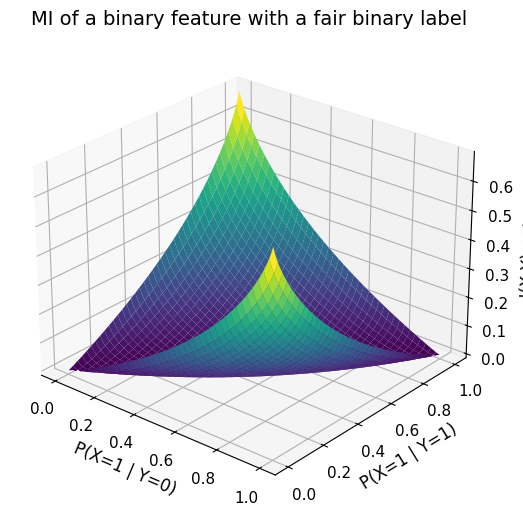

maximum 0.6852 vs ln 2 = 0.6931 | value on the diagonal: 0.0


In [6]:
aa, bb = np.meshgrid(np.linspace(0.001, 0.999, 120), np.linspace(0.001, 0.999, 120))
def mi_ab(a_, b_):
    j = np.stack([0.5 * (1 - a_), 0.5 * a_, 0.5 * (1 - b_), 0.5 * b_]); px1 = 0.5 * (a_ + b_); pxm = np.stack([1 - px1, px1, 1 - px1, px1])
    return np.sum(j * np.log(j / (0.5 * pxm)), axis=0)
MIab = mi_ab(aa, bb); fig = plt.figure(figsize=(8.8, 6.2)); ax = fig.add_subplot(projection="3d"); ax.plot_surface(aa, bb, MIab, cmap="viridis", edgecolor="none"); ax.set_xlabel("P(X=1 | Y=0)"); ax.set_ylabel("P(X=1 | Y=1)"); ax.set_zlabel("I(X;Y) nats"); ax.set_title("MI of a binary feature with a fair binary label"); ax.view_init(elev=26, azim=-50)
plt.show(); print("maximum", MIab.max().round(4), "vs ln 2 =", round(np.log(2), 4), "| value on the diagonal:", np.abs(np.diag(MIab)).max()); assert MIab.max() < np.log(2) + 1e-9 and np.abs(np.diag(MIab)).max() < 1e-12

### 9.2 Interactive Plotly version of 9.1

In [7]:
fig = go.Figure(go.Surface(x=aa[0], y=bb[:, 0], z=MIab, colorscale="Viridis")); fig.update_layout(title="I(X;Y) for a binary feature", width=760, height=560, scene=dict(xaxis_title="P(X=1|Y=0)", yaxis_title="P(X=1|Y=1)", zaxis_title="MI (nats)")); fig.show()

### 9.3 Static: joint distribution and the independent product
For two ordinal variables with a dependent joint pmf (left) and the product of its marginals (right); MI is the KL divergence from the right to the left.

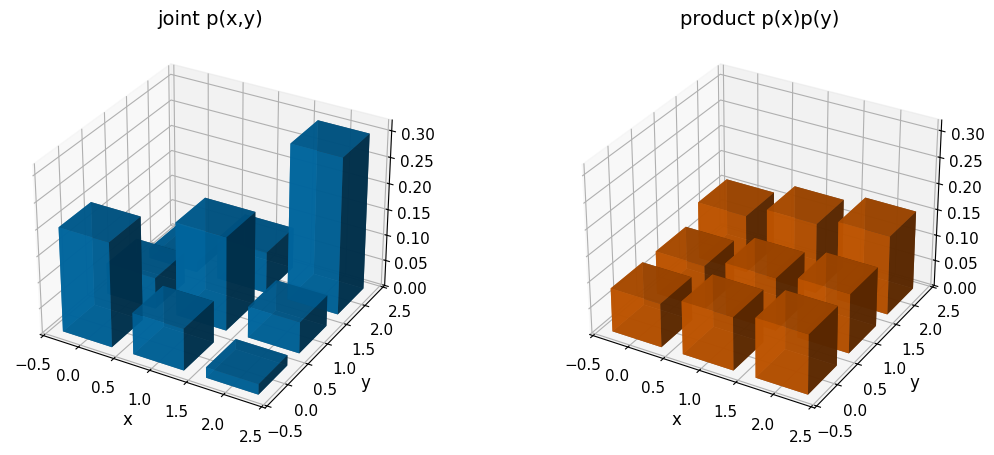

I = KL(joint || product) = 0.2899 nats, NMI = 0.2659


In [8]:
Pj = np.array([[0.20, 0.08, 0.02], [0.06, 0.18, 0.06], [0.02, 0.08, 0.30]]); Pj /= Pj.sum(); Pp = np.outer(Pj.sum(1), Pj.sum(0)); fig = plt.figure(figsize=(13, 5.2)); X3, Y3 = np.meshgrid(range(3), range(3))
for i, (P_, nm) in enumerate([(Pj, f"joint p(x,y)"), (Pp, "product p(x)p(y)")]): ax = fig.add_subplot(1, 2, i + 1, projection="3d"); ax.bar3d(X3.ravel() - 0.35, Y3.ravel() - 0.35, np.zeros(9), 0.7, 0.7, P_.ravel(), color=[MAIN, HIGHLIGHT][i], alpha=0.85); ax.set_title(nm); ax.set_zlim(0, 0.32); ax.set_xlabel("x"); ax.set_ylabel("y")
plt.show(); I3 = mi_table(Pj); print(f"I = KL(joint || product) = {I3:.4f} nats, NMI = {I3 / np.sqrt(ent(Pj.sum(1)) * ent(Pj.sum(0))):.4f}"); assert abs(I3 - stats.entropy(Pj.ravel(), Pp.ravel())) < 1e-12 and I3 > 0.2

## 10. Simulation vs theory

### 10.1 The plug-in estimate is biased upwards
For two *independent* variables with $r$ and $c$ categories the plug-in $\hat I$ has mean about $\frac{(r-1)(c-1)}{2n}$ and $2n\hat I\sim\chi^2_{(r-1)(c-1)}$. Check with $r=c=5$ and $n=200$ and $800$.

In [9]:
g = np.random.default_rng(11); rows = []
for n_ in (200, 800):
    Ihat = np.array([mi_table(g.multinomial(n_, np.full(25, 1 / 25)).reshape(5, 5)) for _ in range(20_000)]); rows.append((n_, Ihat.mean(), 16 / (2 * n_), np.var(2 * n_ * Ihat), 2 * 16, np.mean(2 * n_ * Ihat > stats.chi2.ppf(0.95, 16))))
print(pd.DataFrame(rows, columns=["n", "mean I-hat", "(r-1)(c-1)/(2n)", "var of 2n I-hat", "chi2 variance", "P(2n I-hat > chi2 95%)"]).round(4).to_string(index=False))
assert all(abs(r[1] - r[2]) < 0.1 * r[2] for r in rows) and all(abs(r[5] - 0.05) < 0.02 for r in rows)

  n  mean I-hat  (r-1)(c-1)/(2n)  var of 2n I-hat  chi2 variance  P(2n I-hat > chi2 95%)
200      0.0415             0.04          34.7877             32                  0.0650
800      0.0101             0.01          32.1478             32                  0.0522


### 10.2 Data processing: coarsening never increases MI
Take a dependent pair, then merge categories of $Y$ step by step; the MI with $X$ can only decrease.

In [10]:
Pb = np.array([[0.12, 0.05, 0.02, 0.01], [0.05, 0.12, 0.05, 0.01], [0.01, 0.05, 0.12, 0.05], [0.01, 0.02, 0.05, 0.12]]); Pb /= Pb.sum()
steps = [Pb, np.column_stack([Pb[:, 0] + Pb[:, 1], Pb[:, 2], Pb[:, 3]]), np.column_stack([Pb[:, 0] + Pb[:, 1], Pb[:, 2] + Pb[:, 3]]), Pb.sum(axis=1, keepdims=True)]; mis = [mi_table(s) for s in steps]; print("MI after merging categories of Y (4, 3, 2, 1 categories):", np.round(mis, 4)); assert all(mis[i] >= mis[i + 1] - 1e-12 for i in range(3)) and abs(mis[-1]) < 1e-12

MI after merging categories of Y (4, 3, 2, 1 categories): [0.2896 0.2396 0.1895 0.    ]


### 10.3 Number of bins changes the plug-in estimate
For correlated Gaussian data ($\rho=0.6$, $n=2{,}000$) the plug-in MI from $b\times b$ equal-frequency bins is **below** the truth $-\frac{1}{2}\ln(1-\rho^2)$ for few bins (coarsening loses information, as in 10.2) and **above** it for many bins (cells with few points inflate the estimate by about $(b-1)^2/(2n)$). Subtracting that bias removes the overshoot; the corrected estimate then approaches the truth slowly from below. There is no single right number of bins: check stability, or use the KSG estimator.

In [11]:
g = np.random.default_rng(12); rho = 0.6; xy = g.multivariate_normal([0, 0], [[1, rho], [rho, 1]], 2000); true_i = -0.5 * np.log(1 - rho ** 2); out = []
for b_ in (2, 3, 5, 8, 12, 20, 40):
    qx = np.searchsorted(np.quantile(xy[:, 0], np.linspace(0, 1, b_ + 1)[1:-1]), xy[:, 0]); qy = np.searchsorted(np.quantile(xy[:, 1], np.linspace(0, 1, b_ + 1)[1:-1]), xy[:, 1]); C = np.zeros((b_, b_)); np.add.at(C, (qx, qy), 1); i_ = mi_table(C); out.append((b_, i_, i_ - (b_ - 1) ** 2 / (2 * 2000)))
print(f"true I = {true_i:.4f}"); print(pd.DataFrame(out, columns=["bins per variable", "plug-in", "bias-corrected"]).round(4).to_string(index=False)); assert out[0][1] < true_i < out[-1][1] and all(o[2] < true_i for o in out) and out[-1][2] > out[2][2] > out[0][2]

true I = 0.2231
 bins per variable  plug-in  bias-corrected
                 2   0.0717          0.0714
                 3   0.1098          0.1088
                 5   0.1354          0.1314
                 8   0.1655          0.1533
                12   0.1987          0.1685
                20   0.2679          0.1776
                40   0.6010          0.2207


## 11. `scipy` and NumPy cheat sheet for this lesson

In [12]:
print("table MI: scipy.stats.entropy(P.ravel(), np.outer(P.sum(1), P.sum(0)).ravel()) | G-test of independence: scipy.stats.chi2_contingency(table, lambda_='log-likelihood')")
tb = np.array([[30, 10], [20, 40]]); gs = stats.chi2_contingency(tb, correction=False, lambda_="log-likelihood"); print("G =", gs[0], "| 2 n I =", 2 * tb.sum() * mi_table(tb), "| p =", gs[1], "| dof =", gs[2])
print("continuous pairs: the KSG estimator above (sklearn.feature_selection.mutual_info_regression is the library version) | NMI = I / sqrt(H(X) H(Y))")
print("information gain of a split: H(y) - sum_k (n_k / n) H(y | split k)")
assert abs(gs[0] - 2 * tb.sum() * mi_table(tb)) < 1e-9

table MI: scipy.stats.entropy(P.ravel(), np.outer(P.sum(1), P.sum(0)).ravel()) | G-test of independence: scipy.stats.chi2_contingency(table, lambda_='log-likelihood')
G = 17.260924347106844 | 2 n I = 17.260924347106837 | p = 3.258188094698204e-05 | dof = 1
continuous pairs: the KSG estimator above (sklearn.feature_selection.mutual_info_regression is the library version) | NMI = I / sqrt(H(X) H(Y))
information gain of a split: H(y) - sum_k (n_k / n) H(y | split k)


## 12. Real-world worked examples

---
### Example 1 (main): which features tell us about churn?

**Scenario.** A telecom has 5,000 customers and six candidate features: **tenure** (months), **support calls**, **monthly charge**, **age**, **region** (5 codes, pure noise) and **charge_copy** (the monthly charge plus a little noise, a redundant duplicate). Churn rises with short tenure and with support calls, falls slightly with a high charge, and is **U-shaped in age** (young and old customers leave more often).

**Questions**
1. Rank the features by $|\text{correlation with churn}|$ and by mutual information with churn (10 equal-frequency bins for continuous features, bias-corrected).
2. Which MI values are significantly above the noise level (99th percentile of 300 permutations)?
3. How redundant are charge and charge_copy? What is the MI between them?
4. Which features would you keep for a model?

### 12.1 By hand
With 10 bins and 2 labels the plug-in bias is $(10-1)(2-1)/(2\cdot5000)=0.0009$ nats, so any MI below about 0.001 nats is noise-sized. Correlation measures only a straight-line trend: for the U-shaped age effect it should be close to zero although churn depends strongly on age. A duplicate feature shares most of the 2.30 nats ($=\ln10$) of the charge bins with the original (the small extra noise only blurs some bin edges), so it adds almost nothing once charge is known.

In [13]:
g = np.random.default_rng(21); n1 = 5000
tenure = np.minimum(g.gamma(2.0, 12.0, n1) + 1, 72); calls = g.poisson(1.5, n1); charge = np.clip(g.normal(70, 20, n1), 20, None); age = g.uniform(18, 80, n1); region = g.integers(0, 5, n1); copy = charge + g.normal(0, 2, n1)
logit = -2.6 - 0.05 * (tenure - 24) + 0.45 * calls - 0.012 * (charge - 70) + 0.0022 * (age - 49) ** 2; churn = (g.random(n1) < 1 / (1 + np.exp(-logit))).astype(int)
feats = {"tenure": tenure, "calls": calls, "charge": charge, "age": age, "region": region, "charge_copy": copy}
def binned(v, b=10): return np.searchsorted(np.quantile(v, np.linspace(0, 1, b + 1)[1:-1]), v) if len(np.unique(v)) > 12 else np.unique(v, return_inverse=True)[1]
def mi_cat(a_, y_):
    C = np.zeros((a_.max() + 1, y_.max() + 1)); np.add.at(C, (a_, y_), 1); return mi_table(C), (C.shape[0] - 1) * (C.shape[1] - 1) / (2 * len(a_))
tab = []; B = {k: binned(v) for k, v in feats.items()}
for k, v in feats.items():
    m_, bias = mi_cat(B[k], churn); perm = [mi_cat(g.permutation(B[k]), churn)[0] for _ in range(300)]; tab.append({"feature": k, "|pearson|": abs(np.corrcoef(v, churn)[0, 1]), "|spearman|": abs(stats.spearmanr(v, churn)[0]), "MI plug-in": m_, "bias (r-1)(c-1)/2n": bias, "MI corrected": m_ - bias, "permutation 99%": np.quantile(perm, 0.99), "significant": m_ > np.quantile(perm, 0.99)})
tab = pd.DataFrame(tab).set_index("feature"); print(f"churn rate {churn.mean():.3f}, H(churn) = {ent([1 - churn.mean(), churn.mean()]):.4f} nats"); print(tab.round(4).to_string())
print("rank by |pearson|:", list(tab["|pearson|"].sort_values(ascending=False).index)); print("rank by MI:", list(tab["MI corrected"].sort_values(ascending=False).index))
Cc = np.zeros((10, 10)); np.add.at(Cc, (B["charge"], B["charge_copy"]), 1); print(f"Q3: I(charge; charge_copy) = {mi_table(Cc):.4f} nats vs H(charge bins) = {ent(Cc.sum(1) / Cc.sum()):.4f}")

churn rate 0.278, H(churn) = 0.5911 nats
             |pearson|  |spearman|  MI plug-in  bias (r-1)(c-1)/2n  MI corrected  permutation 99%  significant
feature                                                                                                       
tenure          0.2389      0.2392      0.0325              0.0009        0.0316           0.0023         True
calls           0.2434      0.2298      0.0294              0.0009        0.0285           0.0021         True
charge          0.0889      0.0903      0.0051              0.0009        0.0042           0.0022         True
age             0.0177      0.0178      0.0219              0.0009        0.0210           0.0018         True
region          0.0030      0.0028      0.0004              0.0004        0.0000           0.0013        False
charge_copy     0.0896      0.0912      0.0044              0.0009        0.0035           0.0023         True
rank by |pearson|: ['calls', 'tenure', 'charge_copy', 'charge', 'age', 

### 12.2 Asserts

In [14]:
assert tab.loc["age", "|pearson|"] < 0.04 and tab.loc["age", "MI corrected"] > 3 * tab.loc["age", "|pearson|"] ** 2 and tab.loc["age", "significant"]
assert not tab.loc["region", "significant"] and tab.loc["region", "MI corrected"] < 0.002 and tab.loc["tenure", "significant"] and tab.loc["calls", "significant"]
assert abs(tab.loc["region", "bias (r-1)(c-1)/2n"] - 4 / 10000) < 1e-12 and mi_table(Cc) > 0.6 * ent(Cc.sum(1) / Cc.sum())
print("all checks passed")

all checks passed


### 12.3 Verify by simulation
The permutation baseline should equal the bias formula: under shuffling the mean plug-in MI of a 10-bin feature with the binary label is about $(10-1)/(2n)$.

In [15]:
nm_ = np.array([mi_cat(g.permutation(B["tenure"]), churn)[0] for _ in range(1000)]); print(f"mean MI after shuffling: {nm_.mean():.5f} | (r-1)(c-1)/(2n) = {9 / 10000:.5f}"); assert abs(nm_.mean() - 9 / 10000) < 0.0002

mean MI after shuffling: 0.00090 | (r-1)(c-1)/(2n) = 0.00090


### 12.4 Plots

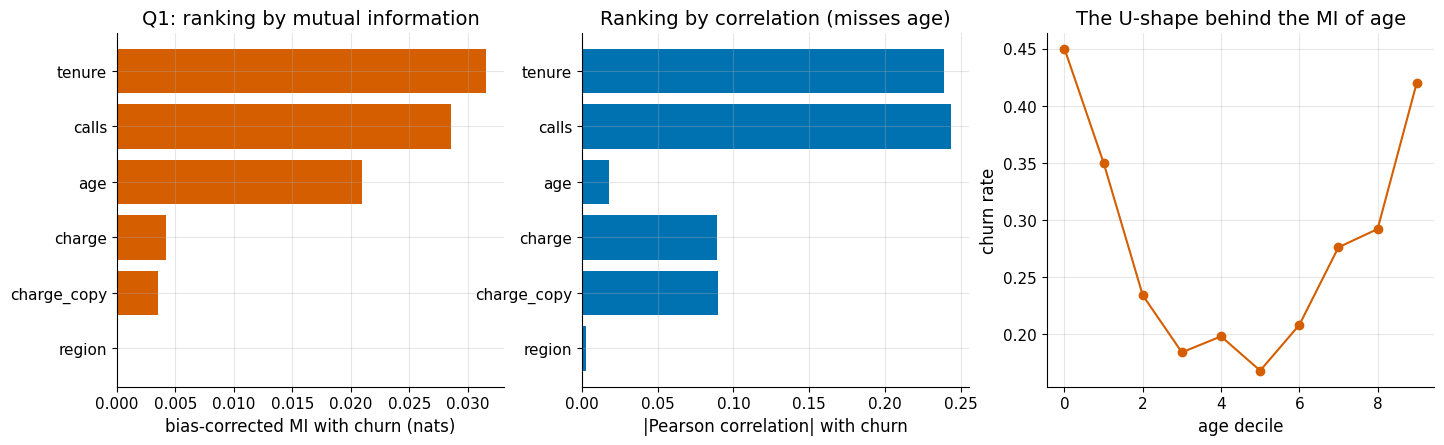

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6)); order = tab["MI corrected"].sort_values(ascending=False).index; axes[0].barh(order[::-1], tab.loc[order[::-1], "MI corrected"], color=HIGHLIGHT); axes[0].set_xlabel("bias-corrected MI with churn (nats)"); axes[0].set_title("Q1: ranking by mutual information")
axes[1].barh(order[::-1], tab.loc[order[::-1], "|pearson|"], color=MAIN); axes[1].set_xlabel("|Pearson correlation| with churn"); axes[1].set_title("Ranking by correlation (misses age)")
ab = np.searchsorted(np.quantile(age, np.linspace(0, 1, 11)[1:-1]), age); rate = [churn[ab == k].mean() for k in range(10)]; axes[2].plot(range(10), rate, "o-", color=HIGHLIGHT); axes[2].set_xlabel("age decile"); axes[2].set_ylabel("churn rate"); axes[2].set_title("The U-shape behind the MI of age")
plt.show()

### 12.5 Interpretation and decision (Example 1)
- Churn is 27.8 % ($H=0.591$ nats). **By correlation** the ranking is calls (0.243), tenure (0.239), the duplicate (0.090), charge (0.089), **age (0.018)** and region (0.003). **By bias-corrected mutual information** it is tenure **0.0316**, calls **0.0285**, **age 0.0210**, charge 0.0042, the copy 0.0035 and region **0.0000**: the U-shaped age effect, invisible to correlation (rank 5 of 6), is the third most informative feature.
- Against the permutation baseline (99th percentile 0.0013 to 0.0023 nats) tenure, calls, age, charge and the copy are significant, while **region is not** (plug-in 0.0004, exactly the bias term $(r-1)(c-1)/(2n)=0.0004$). The shuffled-label MI averages 0.00090, matching the formula $9/(2n)$.
- Charge and its copy share **1.65 of the 2.30 nats** of the charge bins: the copy is largely redundant, and Exercise 6 shows that the pair on a 5x5 grid carries no more information about churn than charge alone (corrected 0.0031 against 0.0044).
- **Decision.** Keep tenure, calls, age (encoded flexibly, for example as bins or a squared term, so that a linear model can use the U-shape) and one of charge or its copy; drop region. A correlation filter would have dropped age.

---
### Example 2: information gain of a split (what a decision tree does)

**Scenario.** 4,000 loan applicants, income in thousands of dollars, $\text{income}\sim N(50,15^2)$. The default probability falls with income: $P(\text{default})=\sigma\big(-(\text{income}-35)/6\big)$.

**Questions.** (1) What is the entropy of the default label? (2) Find the income threshold that maximises the information gain $H(Y)-H(Y\mid S)$ and compare with the Gini criterion's best threshold. (3) What fraction of the label's entropy does this single split remove?

Q1: default rate 0.2042, H(Y) = 0.5062 nats = 0.7303 bits
Q2: best information-gain threshold 43.5 (IG = 0.1447 nats), best Gini threshold 37.5; I(Y; split) from the table 0.1447
Q3: the split removes 28.6% of the entropy of the label | information gain at the Gini threshold: 0.1369 (94.6% of the maximum)


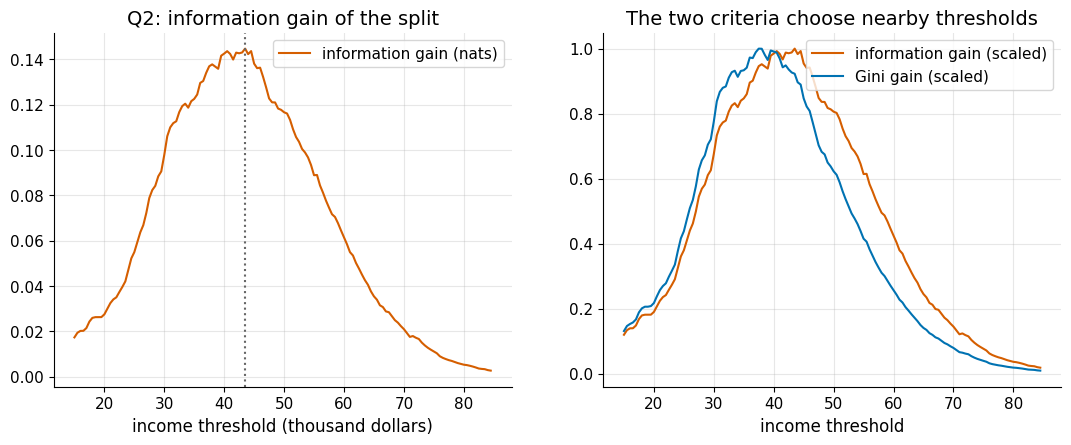

In [17]:
g = np.random.default_rng(22); inc = g.normal(50, 15, 4000); pdef = 1 / (1 + np.exp((inc - 35) / 6)); dflt = (g.random(4000) < pdef).astype(int); py = dflt.mean(); H_y = ent([1 - py, py])
ths = np.arange(15, 85, 0.5); ig = []; gini = []
for t_ in ths:
    s = inc > t_; w = s.mean(); hs = ent([1 - dflt[s].mean(), dflt[s].mean()]) if 0 < s.sum() else 0; hn = ent([1 - dflt[~s].mean(), dflt[~s].mean()]) if 0 < (~s).sum() else 0; ig.append(H_y - (w * hs + (1 - w) * hn))
    gi = lambda m: 2 * m * (1 - m); gini.append(gi(py) - (w * gi(dflt[s].mean()) + (1 - w) * gi(dflt[~s].mean())))
ig = np.array(ig); gini = np.array(gini); t_ig, t_g = ths[np.argmax(ig)], ths[np.argmax(gini)]; Isplit = mi_table(np.histogram2d(inc > t_ig, dflt, bins=[2, 2])[0])
print(f"Q1: default rate {py:.4f}, H(Y) = {H_y:.4f} nats = {H_y / np.log(2):.4f} bits"); print(f"Q2: best information-gain threshold {t_ig} (IG = {ig.max():.4f} nats), best Gini threshold {t_g}; I(Y; split) from the table {Isplit:.4f}"); print(f"Q3: the split removes {ig.max() / H_y:.1%} of the entropy of the label | information gain at the Gini threshold: {ig[ths == t_g][0]:.4f} ({ig[ths == t_g][0] / ig.max():.1%} of the maximum)")
assert abs(ig.max() - Isplit) < 1e-9 and abs(t_ig - t_g) <= 8 and ig.max() < H_y and 20 < t_ig < 50
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6)); axes[0].plot(ths, ig, color=HIGHLIGHT, label="information gain (nats)"); axes[0].axvline(t_ig, color=NEUTRAL, linestyle=":"); axes[0].set_xlabel("income threshold (thousand dollars)"); axes[0].legend(); axes[0].set_title("Q2: information gain of the split")
axes[1].plot(ths, ig / ig.max(), color=HIGHLIGHT, label="information gain (scaled)"); axes[1].plot(ths, gini / gini.max(), color=MAIN, label="Gini gain (scaled)"); axes[1].legend(); axes[1].set_xlabel("income threshold"); axes[1].set_title("The two criteria choose nearby thresholds")
plt.show()

### 12.7 Interpretation and decision (Example 2)
- The default label has a rate of 20.4 % and an entropy of **0.506 nats (0.730 bits)**. The best information-gain threshold is an income of **43.5 thousand**, with a gain of **0.145 nats**; the Gini criterion picks **37.5 thousand**, whose information gain is 0.137 nats, **94.6 %** of the maximum. The gain computed as the mutual information of the label with the split indicator (0.1447) equals the direct computation.
- A single income split removes **28.6 %** of the entropy of the label; the remaining 71 % must come from other features or finer splits.
- **Decision.** A decision tree chooses splits by this information gain (or Gini); the two criteria agree on the shape but differ by a few thousand in the threshold because the gain curve is flat near its maximum, so the threshold should be treated as a range and checked with cross-validation.

---
### Example 3: are device and purchase associated? (the G-test is a mutual information)

**Scenario.** A shop logged 4,300 visits: mobile (2,000 visits, 150 purchases), desktop (1,600 visits, 220 purchases) and tablet (700 visits, 60 purchases).

**Questions.** (1) Compute $\hat I$, $G=2n\hat I$ and its p-value, and check them against `chi2_contingency` with the log-likelihood option. (2) Compute the normalised MI and Cramer's V. (3) Is the association strong or weak, and how large is the noise level of $\hat I$ for this table?

Q1: I = 0.00458 nats, G = 39.387, p = 2.801e-09 | scipy: G = 39.387, p = 2.801e-09, Pearson chi2 = 40.476
Q2: NMI = 0.00796, Cramer's V = 0.0970 | Q3: noise level (r-1)(c-1)/(2n) = 0.00023 nats; purchase rates by device: [0.075  0.1375 0.0857]
simulated null mean 0.00024, 95th percentile 0.00074 | observed I 0.00458


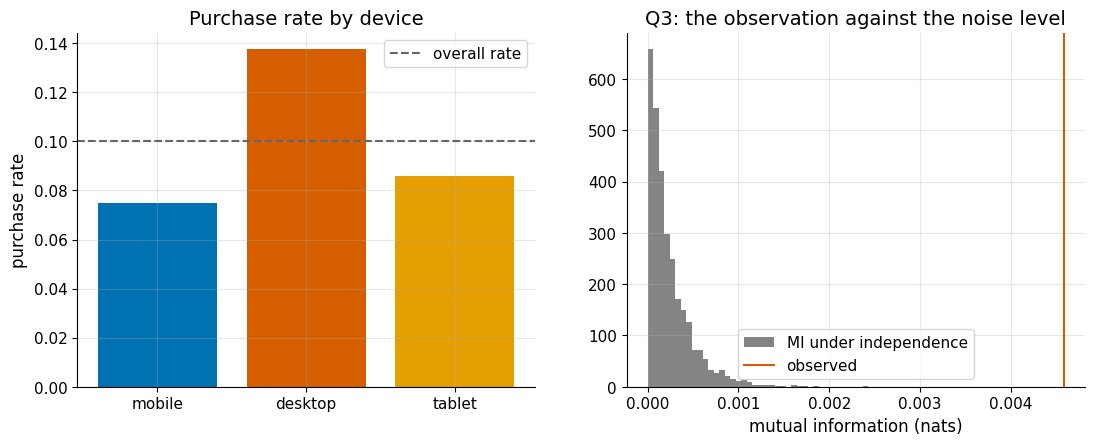

In [18]:
tab3 = np.array([[1850, 150], [1380, 220], [640, 60]]); n3 = tab3.sum(); I3 = mi_table(tab3); G3 = 2 * n3 * I3; p3 = stats.chi2.sf(G3, 2); chk = stats.chi2_contingency(tab3, correction=False, lambda_="log-likelihood"); pear = stats.chi2_contingency(tab3, correction=False)
nmi = I3 / np.sqrt(ent(tab3.sum(1) / n3) * ent(tab3.sum(0) / n3)); cv = np.sqrt(pear[0] / (n3 * 1)); noise = 2 / (2 * n3)
print(f"Q1: I = {I3:.5f} nats, G = {G3:.3f}, p = {p3:.3e} | scipy: G = {chk[0]:.3f}, p = {chk[1]:.3e}, Pearson chi2 = {pear[0]:.3f}")
print(f"Q2: NMI = {nmi:.5f}, Cramer's V = {cv:.4f} | Q3: noise level (r-1)(c-1)/(2n) = {noise:.5f} nats; purchase rates by device: {np.round(tab3[:, 1] / tab3.sum(1), 4)}")
g = np.random.default_rng(23); nulls = np.array([mi_table(g.multinomial(n3, (tab3.sum(1)[:, None] * tab3.sum(0)[None, :] / n3 ** 2).ravel()).reshape(3, 2)) for _ in range(3000)]); print(f"simulated null mean {nulls.mean():.5f}, 95th percentile {np.quantile(nulls, 0.95):.5f} | observed I {I3:.5f}")
assert abs(G3 - chk[0]) < 1e-9 and abs(p3 - chk[1]) < 1e-12 and p3 < 0.001 and abs(nulls.mean() - noise) < 0.0001 and I3 > np.quantile(nulls, 0.99)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6)); axes[0].bar(["mobile", "desktop", "tablet"], tab3[:, 1] / tab3.sum(1), color=[MAIN, HIGHLIGHT, SIM]); axes[0].axhline(tab3[:, 1].sum() / n3, color=NEUTRAL, linestyle="--", label="overall rate"); axes[0].set_ylabel("purchase rate"); axes[0].legend(); axes[0].set_title("Purchase rate by device")
axes[1].hist(nulls, bins=40, color=NEUTRAL, alpha=0.8, label="MI under independence"); axes[1].axvline(I3, color=HIGHLIGHT, label="observed"); axes[1].set_xlabel("mutual information (nats)"); axes[1].legend(); axes[1].set_title("Q3: the observation against the noise level")
plt.show()

### 12.9 Interpretation and decision (Example 3)
- The mutual information of device and purchase is **0.00458 nats**, $G=2n\hat I=$ **39.39** with 2 degrees of freedom and a p-value of **$2.8\times10^{-9}$**; `chi2_contingency` with the log-likelihood option returns the same $G$ (Pearson's $\chi^2$ is 40.48). The noise level of an independent table of this size is $(r-1)(c-1)/(2n)=0.00023$ nats (simulated mean 0.00024, 95th percentile 0.00074), so the observed value is about 20 times the noise.
- The association is certain but **weak**: NMI **0.008** (device explains under 1 % of the entropy of the purchase decision) and Cramer's V **0.097**. Purchase rates are 7.5 % on mobile, **13.8 % on desktop** and 8.6 % on tablet.
- **Decision.** Device is worth including as a feature and in the segmentation of the shop, but do not expect it to predict individual purchases; a statistically significant association and a large predictive gain are different things.

## 13. Where it is used

### Statistics
- **Tests of independence** (the G-test is $2n\hat I$), measures of association beyond correlation, **information criteria** and **sufficiency** (a statistic is sufficient iff it keeps all the information about the parameter), **channel capacity** in coding theory.

### Data science
- **Feature selection** (filter methods, mRMR), **information gain** in decision trees and random forests, **clustering and segmentation evaluation** (NMI, adjusted MI), detecting **nonlinear dependence** and **leakage**, exploratory screening of many candidate variables.

### ML and AI
- **Representation learning** (InfoNCE and contrastive losses maximise a bound on MI), the **information bottleneck** view of deep networks, **independent component analysis**, mutual-information regularisers in VAEs and GANs (InfoGAN), data-processing inequalities for model compression.

## 14. Common pitfalls and misconceptions

- **Trusting the raw plug-in value:** it is biased up by $(r-1)(c-1)/(2n)$; with many bins and few points MI looks large for independent data (10.1, 10.3). Subtract the bias and compare with a permutation baseline.
- **Choosing the number of bins arbitrarily:** the estimate changes with the binning; use equal-frequency bins, a modest number, and check stability, or use a nearest-neighbour estimator.
- **Reading MI as a correlation:** MI has no sign and no direction; a high MI says the variables are dependent, not how.
- **Comparing MI across variables with different entropies:** a high-cardinality feature (an ID) trivially has large MI with anything in a small sample; normalise (NMI) or use gain ratio.
- **Selecting features one at a time:** redundant features all rank high (charge and its copy) and a pair of features can be informative only together (XOR); use conditional MI or mRMR.
- **Ignoring the data-processing inequality:** no transformation of $Y$ can add information about $X$; apparent gains come from estimation bias.
- **Concluding causality:** MI measures association, not cause.

## 15. Exercises

1. A joint table $\begin{pmatrix}0.4&0.1\\0.1&0.4\end{pmatrix}$: compute $I(X;Y)$ in bits and the NMI.
2. Let $X,Y$ be independent fair bits and $Z=X\oplus Y$ (their XOR). Show from the 8-outcome table that $I(Z;X)=0$ and $I(Z;X,Y)=\ln2$.
3. For $\rho=0.5$ and $\rho=0.99$ compute the mutual information of a bivariate normal, and the correlation that gives 1 nat.
4. A binary split divides 100 patients (40 sick) into groups of 60 (10 sick) and 40 (30 sick). Compute its information gain in bits.
5. Simulate $Y=\sin(2\pi X)+$ noise (sd 0.2) for $X\sim U(0,1)$ and compare the Pearson correlation, the Spearman correlation and the KSG mutual information.
6. (Harder) For the churn data of Example 1, compute $I(\text{churn};\text{charge, charge\_copy})$ on a 5x5-bin grid and compare with $I(\text{churn};\text{charge})$ on 5 bins to show that the duplicate adds almost nothing.

Solutions are at the end.

## 16. Summary table

| Quantity | Formula | Notes |
|---|---|---|
| $I(X;Y)$ | $\sum p\ln\frac{p(x,y)}{p(x)p(y)}$ | KL from independence, $\ge0$ |
| entropy form | $H(X)-H(X\mid Y)$ | uncertainty removed |
| Gaussian | $-\frac12\ln(1-\rho^2)$ | function of correlation only |
| plug-in bias | $\frac{(r-1)(c-1)}{2n}$ | subtract and use permutations |
| G-test | $2n\hat I\sim\chi^2_{(r-1)(c-1)}$ | independence test |
| information gain | $H(Y)-H(Y\mid S)$ | tree splits |
| NMI | $I/\sqrt{H(X)H(Y)}$ | in $[0,1]$ |
| tools | `stats.entropy`, `chi2_contingency`, KSG | |

## Solutions

In [19]:
P1 = np.array([[0.4, 0.1], [0.1, 0.4]]); i1 = mi_table(P1); print(f"1: I = {i1 / np.log(2):.4f} bits, NMI = {i1 / ent(P1.sum(1)):.4f} (H(X) = ln 2)")
J = np.zeros((2, 2, 2)); [J.__setitem__((a_, b_, a_ ^ b_), 0.25) for a_ in (0, 1) for b_ in (0, 1)]; Pxz = J.sum(axis=1); Pxy_z = J.reshape(4, 2)
print(f"2: I(Z;X) = {mi_table(Pxz):.4f}, I(Z; X, Y) = {mi_table(Pxy_z):.4f} = ln 2 = {np.log(2):.4f}")
print(f"3: rho = 0.5: {-0.5 * np.log(1 - 0.25):.4f} nats; rho = 0.99: {-0.5 * np.log(1 - 0.99 ** 2):.4f} nats; 1 nat needs rho = {np.sqrt(1 - np.exp(-2)):.4f}")
Hs = ent([0.4, 0.6]); ig4 = Hs - (0.6 * ent([10 / 60, 50 / 60]) + 0.4 * ent([30 / 40, 10 / 40])); print(f"4: information gain {ig4 / np.log(2):.4f} bits (H(Y) = {Hs / np.log(2):.4f} bits)")
g = np.random.default_rng(31); xs_ = g.uniform(0, 1, 2000); ys_ = np.sin(2 * np.pi * xs_) + 0.2 * g.normal(size=2000); print(f"5: Pearson {np.corrcoef(xs_, ys_)[0, 1]:.3f}, Spearman {stats.spearmanr(xs_, ys_)[0]:.3f}, KSG MI {ksg(xs_, ys_):.3f} nats")
b5 = lambda v: np.searchsorted(np.quantile(v, np.linspace(0, 1, 6)[1:-1]), v); cc = np.zeros((25, 2)); ids = b5(charge) * 5 + b5(copy); np.add.at(cc, (ids, churn), 1); c1 = np.zeros((5, 2)); np.add.at(c1, (b5(charge), churn), 1)
print(f"6: I(churn; charge, copy) on 5x5 bins {mi_table(cc):.4f} (bias {24 / 10000:.4f}) vs I(churn; charge) on 5 bins {mi_table(c1):.4f} (bias {4 / 10000:.4f}): corrected {mi_table(cc) - 24 / 10000:.4f} vs {mi_table(c1) - 4 / 10000:.4f}")
assert abs(mi_table(Pxz)) < 1e-12 and abs(mi_table(Pxy_z) - np.log(2)) < 1e-12 and abs(np.corrcoef(xs_, ys_)[0, 1]) < 0.9 and ksg(xs_, ys_) > 0.5

1: I = 0.2781 bits, NMI = 0.2781 (H(X) = ln 2)
2: I(Z;X) = 0.0000, I(Z; X, Y) = 0.6931 = ln 2 = 0.6931
3: rho = 0.5: 0.1438 nats; rho = 0.99: 1.9585 nats; 1 nat needs rho = 0.9299
4: information gain 0.2564 bits (H(Y) = 0.9710 bits)
5: Pearson -0.755, Spearman -0.739, KSG MI 1.167 nats
6: I(churn; charge, copy) on 5x5 bins 0.0055 (bias 0.0024) vs I(churn; charge) on 5 bins 0.0048 (bias 0.0004): corrected 0.0031 vs 0.0044


**1.** $I=$ **0.2781 bits**; $\mathrm{NMI}=I/H(X)=0.2781$ (here $H(X)=H(Y)=1$ bit).

**2.** $I(Z;X)=$ **0** (XOR with an independent fair bit hides $X$), but $I(Z;X,Y)=$ **0.6931 $=\ln2$**: $Z$ is determined by the pair. Each feature is useless alone and perfectly informative together.

**3.** $\rho=0.5$: **0.1438 nats**; $\rho=0.99$: **1.9585 nats**; one nat needs $\rho=\sqrt{1-e^{-2}}=$ **0.9299**.

**4.** $H(Y)=0.9710$ bits; the split's information gain is **0.2564 bits** (26 % of the entropy).

**5.** Pearson **-0.755**, Spearman **-0.739** and a KSG mutual information of **1.167 nats**, which for Gaussian data would correspond to $\rho=\sqrt{1-e^{-2\cdot1.167}}=0.95$: the dependence is stronger and more regular than the straight-line correlation suggests.

**6.** The 5x5 grid gives 0.0055 nats (bias 0.0024) against 0.0044 for charge on 5 bins (bias 0.0004): after the bias correction the pair is *not* more informative (0.0031 against 0.0044), so the duplicate adds nothing.